In [16]:
import pandas as pd
import scipy.stats as sc
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

godziny_nauki: 5.3626249999999995,2.765077640749894,1.05,15.0,0.7737398012246204
sredni_wynik_testow: 62.401875,9.149375128082518,43.6,88.0,0.7737398012246204


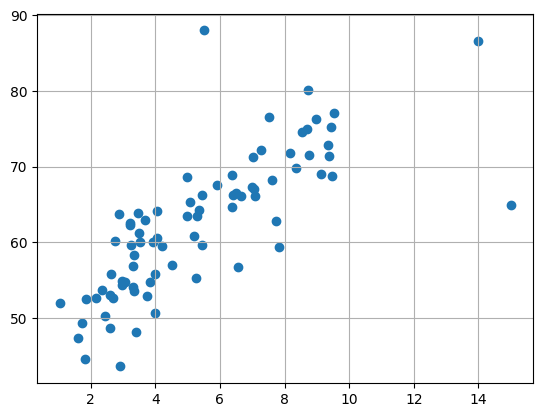

In [17]:
dane = pd.read_csv('zadanie1.csv')
for kolumna in {'godziny_nauki','sredni_wynik_testow'}:
    srednia = np.mean(dane[kolumna])
    odchylenie_standardowe = np.std(dane[kolumna])
    minimum = np.min(dane[kolumna])
    maksimum = np.max(dane[kolumna])
    wspolczynnik_pearsona = sc.pearsonr(dane['godziny_nauki'], dane['sredni_wynik_testow'])[0]
    print(f'{kolumna}: {srednia},{odchylenie_standardowe},{minimum},{maksimum},{wspolczynnik_pearsona}')

plt.scatter(dane['godziny_nauki'], dane['sredni_wynik_testow'])
plt.grid()
plt.show()

48.67231972519258 2.5602303489070026


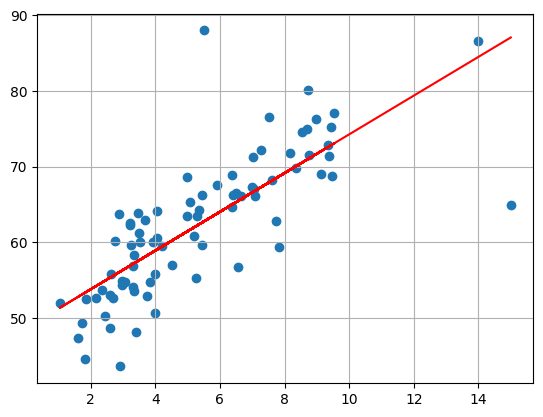

In [18]:
kolumna_x = dane['godziny_nauki']
kolumna_y = dane['sredni_wynik_testow']

def estymatory_MNK_wspolczynnikow(kolumna_x,kolumna_y):
    y_srednie = np.mean(kolumna_y)
    x_srednie = np.mean(kolumna_x)
    y_odjac_srednie = kolumna_y - y_srednie
    x_odjac_srednie = kolumna_x - x_srednie
    x_odjac_srednie_kwadrat = x_odjac_srednie ** 2
    x_razy_y_odjac_srednie = x_odjac_srednie * y_odjac_srednie

    b_1 = np.sum(x_razy_y_odjac_srednie) / np.sum(x_odjac_srednie_kwadrat)
    b_0 = y_srednie - b_1 * x_srednie

    return b_0,b_1

b_0 , b_1 = estymatory_MNK_wspolczynnikow(kolumna_x,kolumna_y)

print(b_0,b_1)

plt.scatter(dane['godziny_nauki'], dane['sredni_wynik_testow'])
plt.plot(kolumna_x, b_0 + b_1 * kolumna_x,color='red')
plt.grid()
plt.show()

In [19]:
model = sm.OLS(kolumna_y, sm.add_constant(kolumna_x)).fit()
model.summary()
print(model.params)





const            48.67232
godziny_nauki     2.56023
dtype: float64


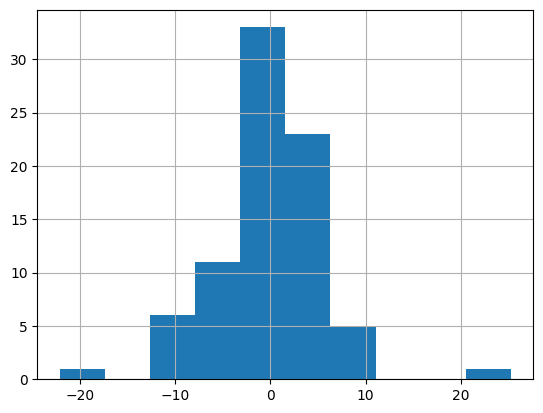

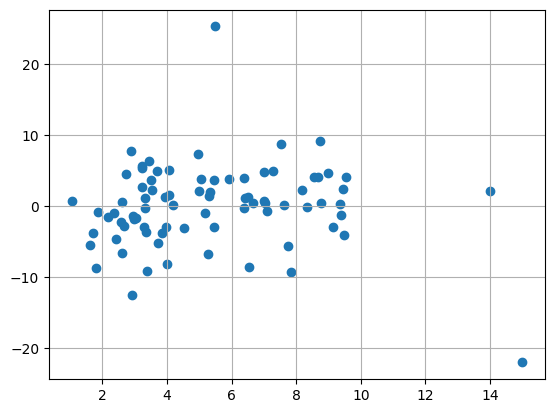

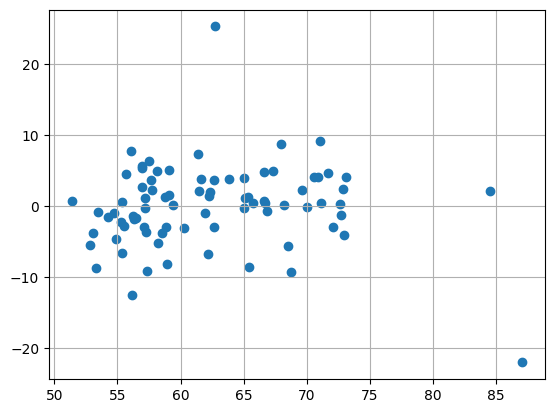

In [20]:
y_z_daszkiem = b_0 + b_1 * kolumna_x

residua = kolumna_y - y_z_daszkiem

plt.hist(residua, bins=10)
plt.grid()
plt.show()
plt.scatter(kolumna_x, residua)
plt.grid()
plt.show()
plt.scatter(y_z_daszkiem, residua)
plt.grid()
plt.show()

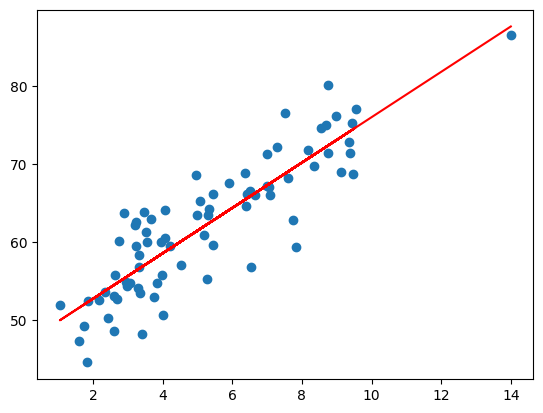

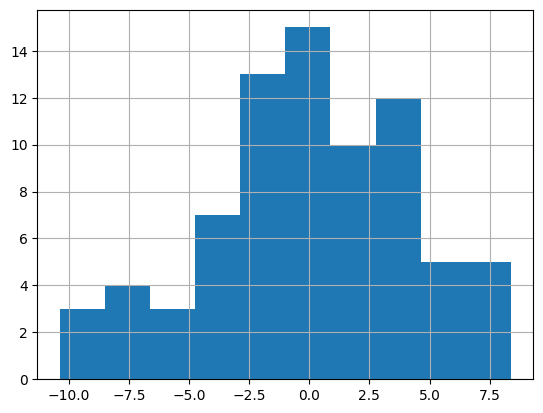

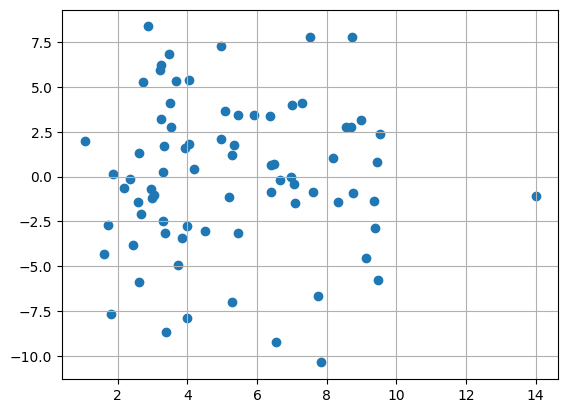

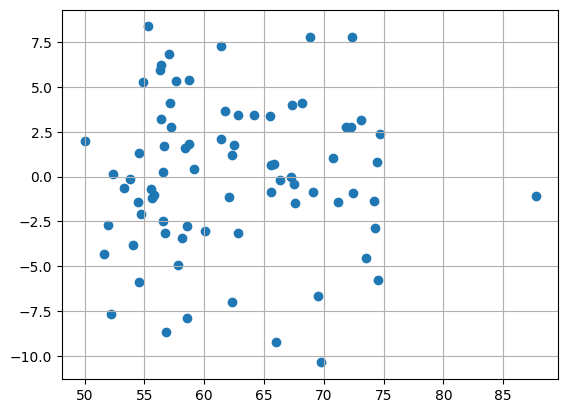

In [21]:
indeksy_do_wycinki = np.where(np.abs(residua) > 10)[0]
model_uciety = dane

model_uciety = model_uciety.drop(indeksy_do_wycinki)
b_0_uciety , b_1_uciety = estymatory_MNK_wspolczynnikow(model_uciety['godziny_nauki'],model_uciety['sredni_wynik_testow'])


plt.scatter(model_uciety['godziny_nauki'], model_uciety['sredni_wynik_testow'])
plt.plot(model_uciety['godziny_nauki'], b_0_uciety + b_1_uciety * model_uciety['godziny_nauki'],color='red')
plt.show()

y_z_daszkiem_uciety = b_0_uciety + b_1_uciety * model_uciety['godziny_nauki']

residua_uciete = model_uciety['sredni_wynik_testow'] - y_z_daszkiem_uciety

plt.hist(residua_uciete, bins=10)
plt.grid()
plt.show()
plt.scatter(model_uciety['godziny_nauki'], residua_uciete)
plt.grid()
plt.show()
plt.scatter(y_z_daszkiem_uciety, residua_uciete)
plt.grid()
plt.show()


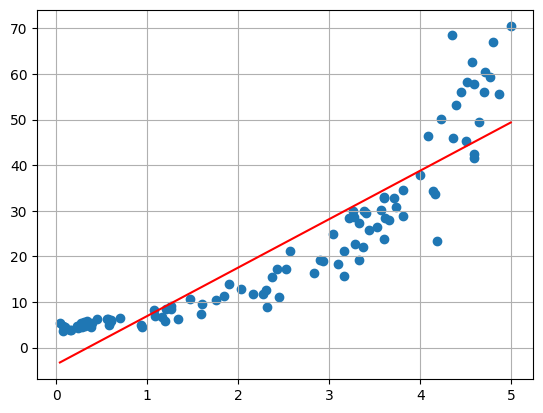

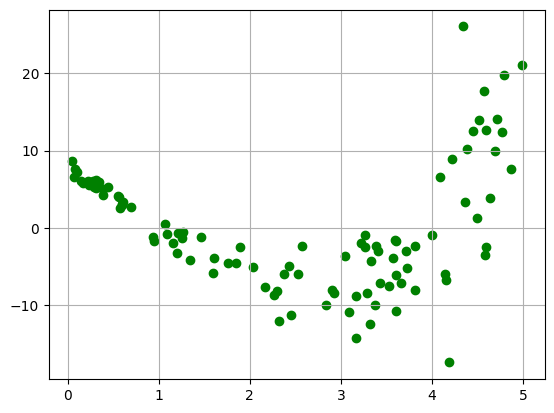

In [25]:
#5a
dane = pd.read_csv('zadanie5.txt', sep=' ', header=None, names=['X','Y'])

b0, b1 = estymatory_MNK_wspolczynnikow(dane['X'], dane['Y'])

Y_z_daszkiem = b0 + b1 * dane['X']

residua = dane['Y'] - Y_z_daszkiem

plt.scatter(dane['X'], dane['Y'])
plt.plot(dane['X'], b0 + b1 * dane['X'], color='red')
plt.grid()
plt.show()

plt.scatter(dane['X'], residua, color='green')
plt.grid()
plt.show()


1.37627927346706 0.5556406534649553


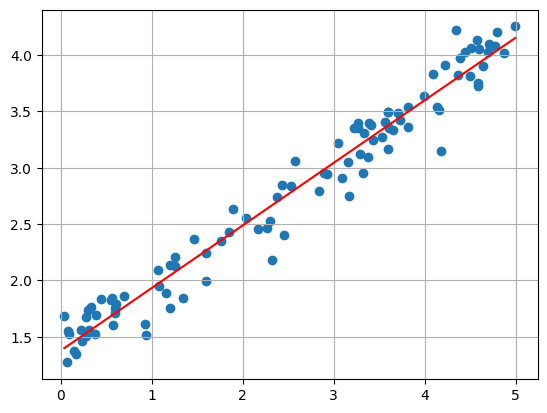

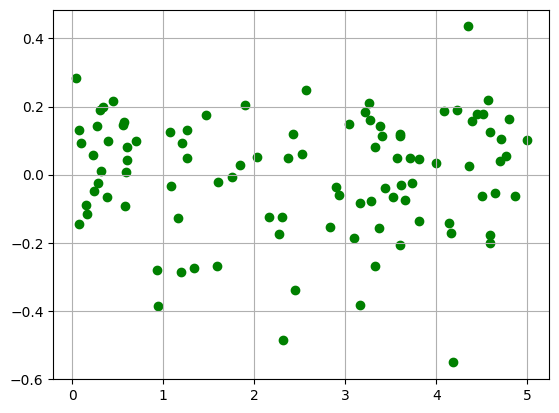

In [36]:
#5b

dane_zmod = dane.copy()

y_mod = np.log(dane_zmod['Y'])

b0_mod, b1_mod = estymatory_MNK_wspolczynnikow(dane_zmod['X'], y_mod)


print(b0_mod,b1_mod)
plt.scatter(dane_zmod['X'], y_mod)
plt.plot(dane_zmod['X'], b0_mod + b1_mod * dane_zmod['X'], color='red')
plt.grid()
plt.show()

Y_z_daszkiem_mod = b0_mod + b1_mod * dane_zmod['X']
plt.scatter(dane_zmod['X'], y_mod - Y_z_daszkiem_mod, color='green')
plt.grid()
plt.show()